<a href="https://colab.research.google.com/github/saket21091998/Project-on-carbon-uptake-mathematical-modeling-of-Global-atmospheric-CO2-Fluxes/blob/Mathematical-modeling/Carbon_uptake_mathematical_modeling_%26_Trend_Decomposition_of_Global_atmospheric_CO2_Fluxes_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

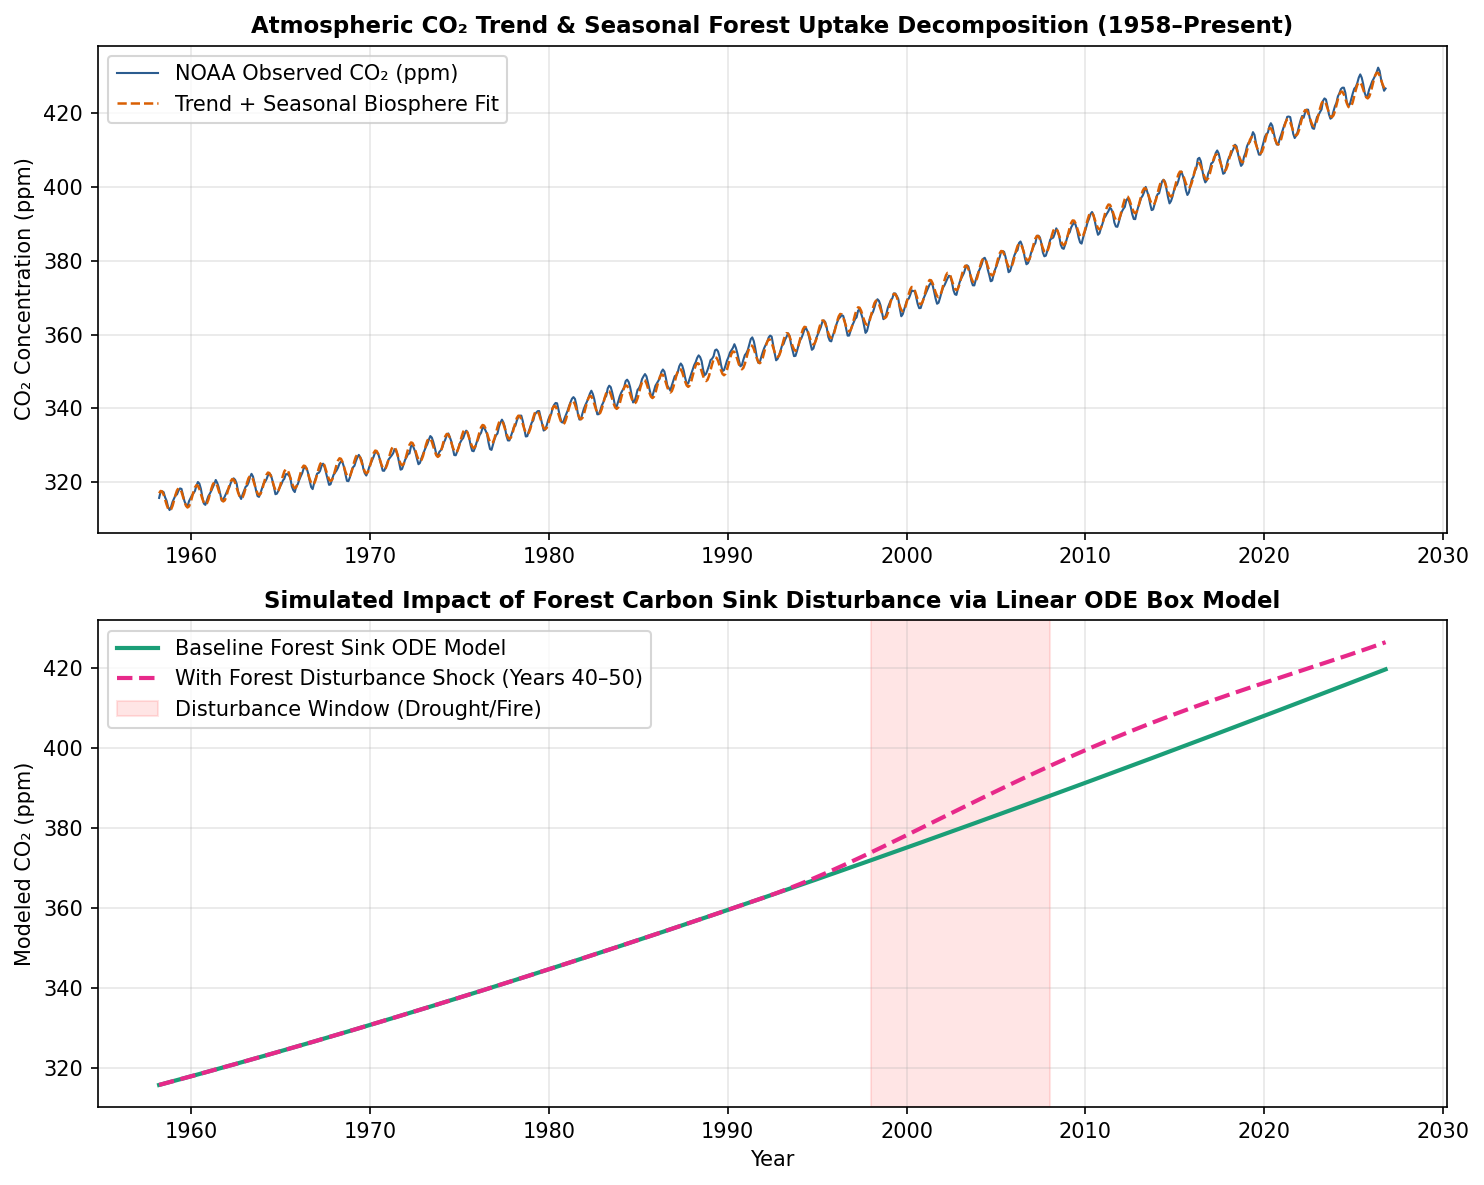

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.integrate import solve_ivp

# 1. Load & Clean Data (skip comment lines starting with '#')
df = pd.read_csv('co2_data.csv', comment='#')
df = df[df['average'] > 0].copy()  # Remove missing values (-99.99)

t = df['decimal date'].values - df['decimal date'].values[0]  # Years since 1958
co2 = df['average'].values

# 2. Mathematical Model: Quadratic Trend + Seasonal Forest Uptake Cycle
def co2_model(t, a0, a1, a2, A, phi):
    trend = a0 + a1 * t + a2 * (t ** 2)
    seasonal_sink = A * np.sin(2 * np.pi * t + phi)
    return trend + seasonal_sink

params, _ = curve_fit(co2_model, t, co2)
co2_pred = co2_model(t, *params)
residuals = co2 - co2_pred

# 3. ODE Box Model of Forest Carbon Sink Under Disturbance
# dC/dt = Emissions(t) - k(t) * (C - C0)
# where k(t) drops during a simulated forest disturbance event
C0 = co2[0]
def carbon_ode(time, C, disturbance=False):
    emissions = 1.2 + 0.035 * time  # Growing anthropogenic input (ppm/yr)
    k_uptake = 0.018                # Baseline forest sink rate (1/yr)
    if disturbance and (40 <= time <= 50):  # 10-year severe drought/fire shock
        k_uptake *= 0.45            # 55% drop in forest carbon uptake
    return emissions - k_uptake * (C - C0)

sol_normal = solve_ivp(carbon_ode, [0, t[-1]], [C0], t_eval=t, args=(False,))
sol_disturbed = solve_ivp(carbon_ode, [0, t[-1]], [C0], t_eval=t, args=(True,))

# 4. Generate Publication-Style Figures
fig, axes = plt.subplots(2, 1, figsize=(10, 8), dpi=150)

# Plot 1: Real Data vs Harmonic Trend Fit
axes[0].plot(df['decimal date'], co2, label='NOAA Observed CO₂ (ppm)', color='#2b5c8f', linewidth=1)
axes[0].plot(df['decimal date'], co2_pred, label='Trend + Seasonal Biosphere Fit', color='#d95f02', linestyle='--', linewidth=1.2)
axes[0].set_title('Atmospheric CO₂ Trend & Seasonal Forest Uptake Decomposition (1958–Present)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('CO₂ Concentration (ppm)')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Plot 2: ODE Simulation of Forest Disturbance Impact
axes[1].plot(df['decimal date'], sol_normal.y[0], label='Baseline Forest Sink ODE Model', color='#1b9e77', linewidth=2)
axes[1].plot(df['decimal date'], sol_disturbed.y[0], label='With Forest Disturbance Shock (Years 40–50)', color='#e7298a', linestyle='--', linewidth=2)
axes[1].axvspan(1958+40, 1958+50, color='red', alpha=0.1, label='Disturbance Window (Drought/Fire)')
axes[1].set_title('Simulated Impact of Forest Carbon Sink Disturbance via Linear ODE Box Model', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Modeled CO₂ (ppm)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('co2_forest_sink_analysis.png')
plt.show()

In [1]:
# Run UNIX command to download real NOAA atmospheric CO2 data
!wget -q https://gml.noaa.gov/webdata/ccgg/trends/co2/co2_mm_mlo.csv -O co2_data.csv
!head -n 45 co2_data.csv

# --------------------------------------------------------------------
# USE OF NOAA GML DATA
#
# These data are made freely available to the public and the scientific
# community in the belief that their wide dissemination will lead to
# greater understanding and new scientific insights. To ensure that GML
# receives fair credit for their work please include relevant citation
# text in publications. We encourage users to contact the data providers,
# who can provide detailed information about the measurements and
# scientific insight.  In cases where the data are central to a
# publication, coauthorship for data providers may be appropriate.
#
#
#
# Contact:  Xin Lan (xin.lan@noaa.gov)
#
# File Creation: Thu Nov 19 14:14:34 2026
#
#
# --------------------------------------------------------------------
#
#
# See gml.noaa.gov/ccgg/trends/ for additional details.
#
# Data from March 1958 through April 1974 have been obtained by C. David Keeling
# of the Scripps Institution of Oceanograp